In [2]:
pip install folium geopy geopandas

Note: you may need to restart the kernel to use updated packages.


In [66]:
import csv
import json
import pandas as pd
import folium 
import math
from geopy.distance import geodesic
import geopandas as gpd
from shapely.geometry import shape
from scipy.spatial.distance import pdist #Permite calcular la Distancia entre puntos
from scipy.spatial import cKDTree #Recherche de plus proches voisins et Métriques de distance
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 1000)
## Funtion de charge general
def charger_prenoms():
#    pd.set_option('display.max_rows', 1000)
    data_prenoms = pd.read_csv('../data/nat2022.csv',
                              sep=';',
                              encoding='utf-8',
                              usecols=['sexe','preusuel', 'annais', 'nombre'])
    return data_prenoms

def charger_departements():
#    pd.set_option('display.max_rows', 1000)
    data_departements = pd.read_csv('../data/dpt2022.csv',
                              sep=';',
                              encoding='utf-8',
                              usecols=['sexe','preusuel', 'annais', 'dpt', 'nombre'])
    return data_departements


<h1> Lecture et impression des premières lignes de chaque donnée</h1>


In [2]:
data_prenoms = charger_prenoms()
print('Les prénoms attribués aux enfants nés en France entre 1900 et 2022: \n')
print(data_prenoms.head(),'\n')

print('Les prénoms attribués aux enfants nés en France entre 1900 et 2022 pour département: \n')
data_departements = charger_departements()
print(data_departements.head())

Les prénoms attribués aux enfants nés en France entre 1900 et 2022: 

   sexe        preusuel annais  nombre
0     1  _PRENOMS_RARES   1900    1249
1     1  _PRENOMS_RARES   1901    1342
2     1  _PRENOMS_RARES   1902    1330
3     1  _PRENOMS_RARES   1903    1286
4     1  _PRENOMS_RARES   1904    1430 

Les prénoms attribués aux enfants nés en France entre 1900 et 2022 pour département: 

   sexe        preusuel annais dpt  nombre
0     1  _PRENOMS_RARES   1900  02       7
1     1  _PRENOMS_RARES   1900  04       9
2     1  _PRENOMS_RARES   1900  05       8
3     1  _PRENOMS_RARES   1900  06      23
4     1  _PRENOMS_RARES   1900  07       9


<h1>Lecture et impression des dernières lignes de chaque donnée</h1>

In [4]:
data_prenoms = charger_prenoms()
print('Les prénoms attribués aux enfants nés en France entre 1900 et 2022: \n')
print(data_prenoms.tail(20),'\n')


print('Les prénoms attribués aux enfants nés en France entre 1900 et 2022 pour département: \n')
data_departements = charger_departements()
print(data_departements.tail(20))

print(data_prenoms.query("preusuel == 'SACHA'").head(10),'\n')

print(data_prenoms.info())

Les prénoms attribués aux enfants nés en France entre 1900 et 2022: 

        sexe preusuel annais  nombre
702987     2     ZYNA   XXXX      16
702988     2    ZYNEB   1999       3
702989     2    ZYNEB   2004       4
702990     2    ZYNEB   2005       5
702991     2    ZYNEB   2006       4
702992     2    ZYNEB   2008      11
702993     2    ZYNEB   2010       7
702994     2    ZYNEB   2011       5
702995     2    ZYNEB   2012       8
702996     2    ZYNEB   2013       4
702997     2    ZYNEB   2014      10
702998     2    ZYNEB   2015       7
702999     2    ZYNEB   2016       6
703000     2    ZYNEB   2017       6
703001     2    ZYNEB   2018       5
703002     2    ZYNEB   2019       7
703003     2    ZYNEB   2020       8
703004     2    ZYNEB   2021       6
703005     2    ZYNEB   2022       4
703006     2    ZYNEB   XXXX      19 

Les prénoms attribués aux enfants nés en France entre 1900 et 2022 pour département: 

         sexe preusuel annais  dpt  nombre
3835747     2     ZUR

<h1>Quelle est la proportion totale Femmes / Hommes au cours du temps depuis 1900 </h1>


Le nombre de Femmes est:  43722489 

Le nombre d'hommes est:  44427761 



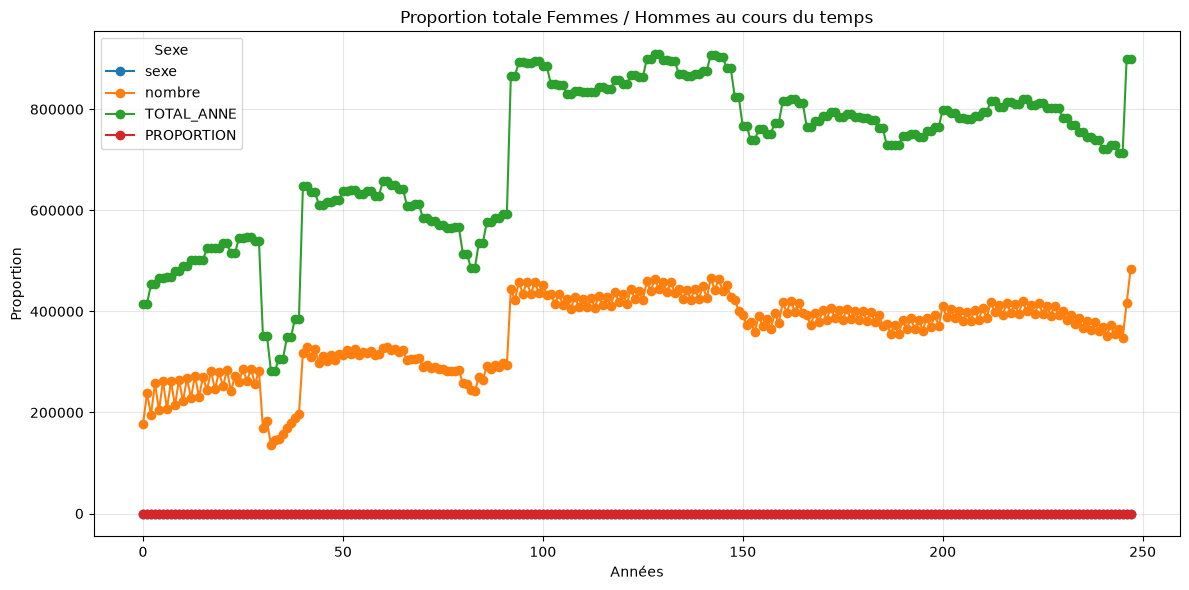

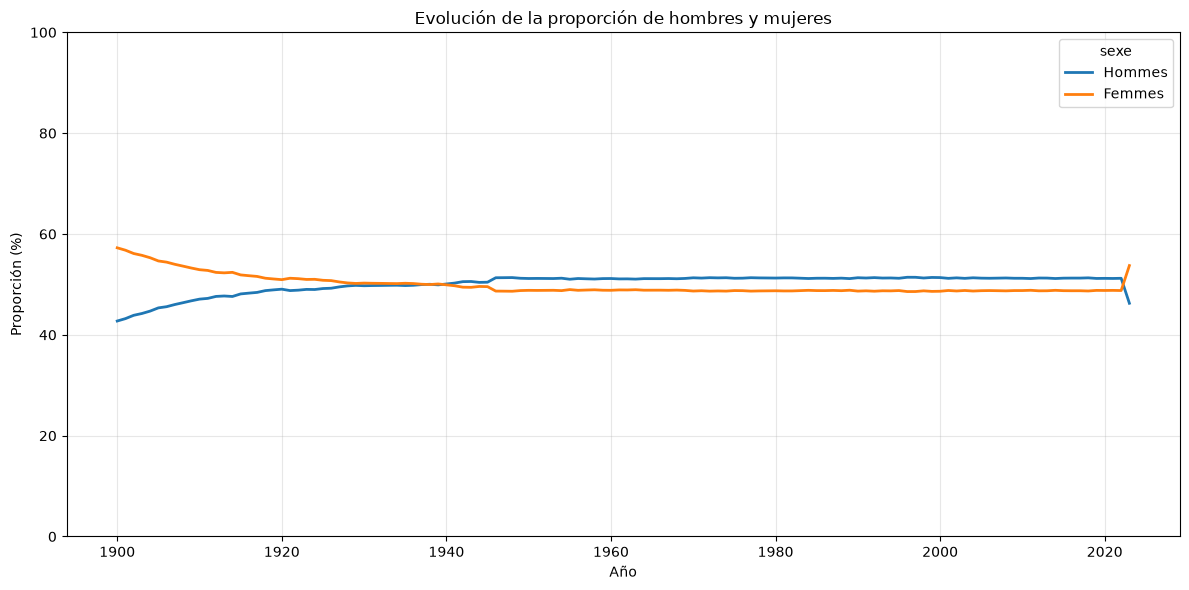

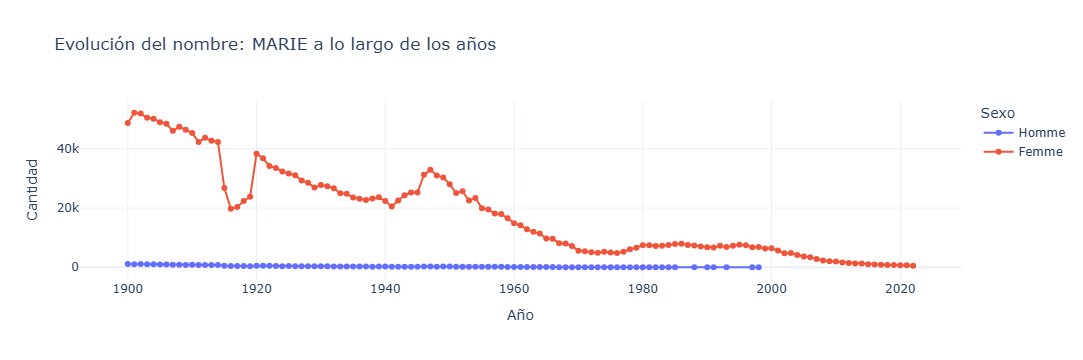

In [57]:
def impression_proportion_departement(proportion):
    proportion.plot(figsize=(12, 6), marker='o')    
    plt.title('Proportion totale Femmes / Hommes au cours du temps pour departements')
    plt.xlabel('Années')
    plt.ylabel('Proportion')
    plt.legend(title='Sexe')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()



def impression_proportion(proporciones):
    proporciones.plot(figsize=(12, 6), marker='o')    
    plt.title('Proportion totale Femmes / Hommes au cours du temps')
    plt.xlabel('Années')
    plt.ylabel('Proportion')
    plt.legend(title='Sexe')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()



def impression_evolue_proportion(evolue_proporciones):
    ax = (evolue_proporciones * 100).plot(
    figsize=(12, 6),
    linewidth=2
    )
    
    ax.set_title('Evolución de la proporción de hombres y mujeres')
    ax.set_xlabel('Año')
    ax.set_ylabel('Proporción (%)')
    ax.set_ylim(0, 100)
    ax.grid(True, alpha=0.3)
    
    # ax = evolue_proporciones.plot(
    # figsize=(12, 6),
    # linewidth=2
    # )  
    # ax.set_title('Evolución de la proporción de hombres y mujeres')
    # ax.set_xlabel('Año')
    # ax.set_ylabel('Proporción')
    # ax.set_ylim(0, 1)
    # ax.legend(title='Sexo')
    # ax.grid(True, alpha=0.3)  
    plt.tight_layout()
    plt.show()




def proportion_femme_homme_total():
    data_prenoms = charger_prenoms()
    # df_prenom = data_prenoms[["sexe","nombre"]].groupby("sexe")
    df_femme = data_prenoms.query("sexe == 2")
    df_homme = data_prenoms.query("sexe == 1")
    nombre_femme = df_femme['nombre'].sum()
    nombre_homme = df_homme['nombre'].sum()

    ### Calculo las proporciones generales hasta hoy por si los necesito
    proporcion_general_f = nombre_femme/(nombre_femme+nombre_homme) 
    proporcion_general_h = nombre_homme/(nombre_femme+nombre_homme) 
    
    print("Le nombre de Femmes est: ", nombre_femme, "\n")
    print("Le nombre d'hommes est: ", nombre_homme, '\n')

    df_prenom = data_prenoms
    df_prenom = (df_prenom.groupby(['annais', 'sexe'])['nombre']
                 .sum()
                 .reset_index()
                )
    df_prenom['TOTAL_ANNE'] = (df_prenom.groupby('annais')['nombre'].transform('sum'))
    df_prenom['PROPORTION'] = ((df_prenom['nombre']/df_prenom['TOTAL_ANNE'])*100) 
    # print(df_prenom.head(10))
    # df_prenom['SEXO_NOMBRE'] = data_prenoms.groupby('sexe')['nombre'].sum()
    # df_prenom['PROPORTION'] = 

    # Sumar el número de personas por año y sexo
    tabla = df_prenom.pivot_table(
        index='annais',
        columns='sexe',
        values='nombre',
        aggfunc='sum',
        fill_value=0
    )
    # Calcular la proporción dentro de cada año
    proporciones = tabla.div(tabla.sum(axis=1), axis=0)   
    # Ordenar cronológicamente los años
    proporciones = proporciones.sort_index()
    proporciones = proporciones.rename(columns={1: 'Hommes', 2: 'Femmes'}) 
    impression_proportion(df_prenom)  
    impression_evolue_proportion(proporciones)
    return df_prenom


    
def proportion_prenom_unique():
    data_prenoms = charger_prenoms()
    df_prenom = data_prenoms.query("preusuel == 'MARIE'")
 
    # df_prenom = data_prenoms
    df_prenom = (df_prenom.groupby(['annais', 'sexe','preusuel'])['nombre']
                 .sum()
                 .reset_index()
                )
    df_prenom['TOTAL_ANNE'] = (df_prenom.groupby('annais')['nombre'].transform('sum'))
    df_prenom['PROPORTION'] = ((df_prenom['nombre']/df_prenom['TOTAL_ANNE'])*100) 

    # Asegurarnos de que el año sea numérico
    df_prenom["annais"] = pd.to_numeric(
        df_prenom["annais"], errors="coerce"
    )
    
    # Etiquetas para los sexos
    df_prenom["sexe"] = df_prenom["sexe"].map({
        1: "Homme",
        2: "Femme"
    }).fillna(df_prenom["sexe"].astype(str))
    
    # Crear el gráfico interactivo
    fig = px.line(
        df_prenom.sort_values("annais"),
        x="annais",
        y="nombre",
        color="sexe",
        markers=True,
        hover_data=["preusuel"],
        title="Evolución del nombre: MARIE a lo largo de los años",
        labels={
            "annais": "Año",
            "nombre": "Número de personas",
            "sexe": "Sexo",
            "preusuel": "Nombre"
        }
    )
    
    fig.update_layout(
        template="plotly_white",
        hovermode="x unified",
        xaxis_title="Año",
        yaxis_title="Cantidad",
        legend_title="Sexo"
    )
    fig.show()
    # return df_prenom




def proportion_femme_homme_departements():
    data_departements = charger_departements()

    df_prenom_depart = data_departements
    # df_prenom_depart.info()
    # df_prenom_depart = (df_prenom_depart.groupby(['annais', 'dpt ','sexe'])['nombre']
    #              .sum()
    #              .reset_index()
    #             )
    # df_prenom_depart['TOTAL_PRENOM_DEPARTEMENT'] = (df_prenom_depart.groupby('annais','dpt')['nombre'].transform('sum'))
    # df_prenom_depart['PROPORTION'] = ((df_prenom_depart['nombre']/df_prenom_depart['TOTAL_ANNE'])*100) 
    # print(df_prenom_depart.head(10))
    # df_prenom['SEXO_NOMBRE'] = data_prenoms.groupby('sexe')['nombre'].sum()
    # df_prenom['PROPORTION'] = 
    # return proportion_prenom_departement





    



    
## Consulto y imprimo la proporcion de mujeres y hombres por années
proporciones = proportion_femme_homme_total()
#print(proporciones)
# print(proporciones.head(10),'\n')

print('\n')

proportion_femme_homme_departements()

proportion_prenom_unique()

In [101]:
data_departements = charger_departements()

df_prenom_depart = data_departements
df_prenom_depart.info() 
df_prenom_depart = (df_prenom_depart.groupby(['annais', 'dpt','sexe'])['nombre']
             .sum()
             .reset_index() 
            )
df_prenom_depart.info()
print(df_prenom_depart.head(10))

df_prenom_depart['TOTAL_PRENOM_DEPARTEMENT'] = (df_prenom_depart.groupby('dpt')['nombre'].transform('sum'))
df_prenom_depart = df_prenom_depart.rename(columns={"TOTAL_PRENOM_DEPARTEMENT":"TOTAL_FEMME_HOMME_DEPARTEMENT"})
df_prenom_depart.info
# df_prenom['PROPORTION'] = ((df_prenom['nombre']/df_prenom['TOTAL_ANNE'])*100) 

<class 'pandas.DataFrame'>
RangeIndex: 3835767 entries, 0 to 3835766
Data columns (total 5 columns):
 #   Column    Dtype
---  ------    -----
 0   sexe      int64
 1   preusuel  str  
 2   annais    str  
 3   dpt       str  
 4   nombre    int64
dtypes: int64(2), str(3)
memory usage: 193.1 MB
<class 'pandas.DataFrame'>
RangeIndex: 23698 entries, 0 to 23697
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   annais  23698 non-null  str  
 1   dpt     23698 non-null  str  
 2   sexe    23698 non-null  int64
 3   nombre  23698 non-null  int64
dtypes: int64(2), str(2)
memory usage: 886.3 KB
  annais dpt  sexe  nombre
0   1900  01     1    1336
1   1900  01     2    1837
2   1900  02     1    2161
3   1900  02     2    2911
4   1900  03     1    1684
5   1900  03     2    2206
6   1900  04     1     442
7   1900  04     2     558
8   1900  05     1     443
9   1900  05     2     562


,annais,dpt,sexe,nombre,TOTAL_FEMME_HOMME_DEPARTEMENT
0,1900,01,1,1336,446745
1,1900,01,2,1837,446745
2,1900,02,1,2161,854501
3,1900,02,2,2911,854501
4,1900,03,1,1684,505234
...,...,...,...,...,...
23693,2022,974,2,4811,1229678
23694,2022,976,1,4276,74630
23695,2022,976,2,3873,74630
23696,XXXX,XX,1,4080537,9104672


<h1>En 2017, on recensait 13.000 prénoms différents, soit 7,6 fois plus qu'en 1900</h1>

 annais  nb_prenoms
 1900.0        1595
 2017.0       13783
Prénoms distincts en 1900 : 1,595
Prénoms distincts en 2017 : 13,783
Facteur de multiplication : 8.64
Augmentation : 764.1 %


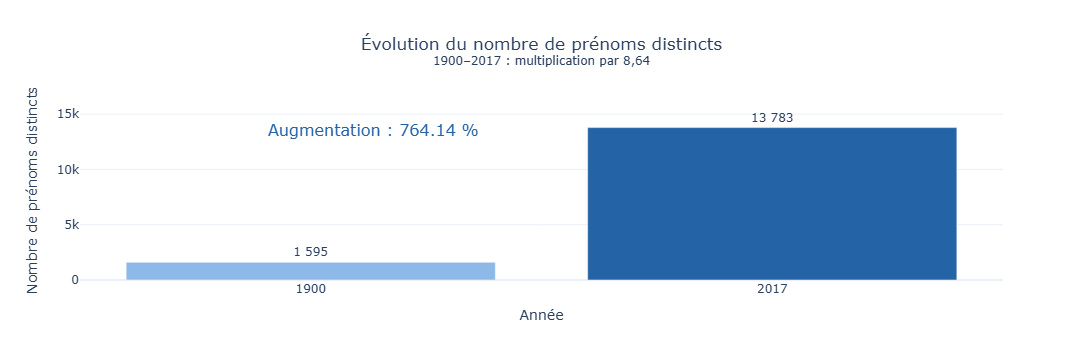

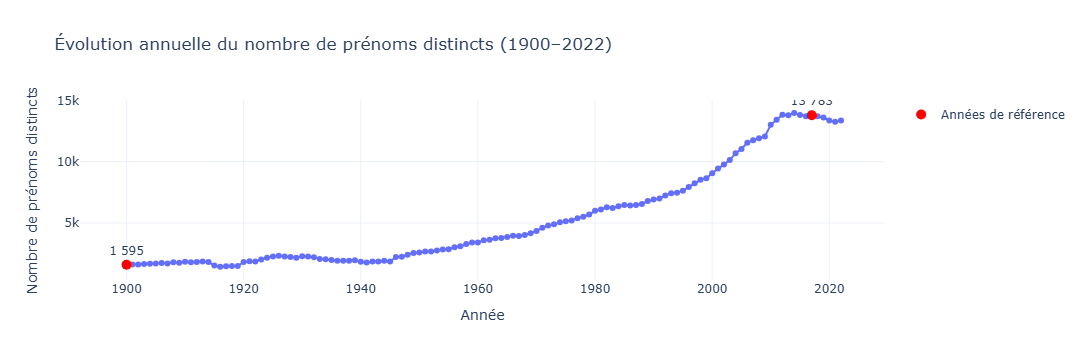

In [97]:
### Creo la funtion que permite generar la grafica de representacion de los
### Prenom en los années 1900 et 2017
def grafique_annes_indique(annees,nombre, augment):
    # annees = ["1900", "2017"]
    # nombres = [1595, 13783]
    
    fig = go.Figure()
    
    fig.add_trace(go.Bar(
        x=annees,
        y=nombre,
        text=[f"{n:,}".replace(",", " ") for n in nombre],
        textposition="outside",
        marker_color=["#8DB9E8", "#2463A6"],
        hovertemplate="Année : %{x}<br>Prénoms distincts : %{y:,}<extra></extra>"
    ))
    
    fig.update_layout(
        title={
            "text": "Évolution du nombre de prénoms distincts<br>"
                    "<sup>1900–2017 : multiplication par 8,64</sup>",
            "x": 0.5
        },
        xaxis_title="Année",
        yaxis_title="Nombre de prénoms distincts",
        template="plotly_white",
        showlegend=False,
        annotations=[
            dict(
                x=0.2,
                y=0.90,
                xref="paper",
                yref="paper",
                text=f"Augmentation : {augment:.2f} %",
                showarrow=False,
                font=dict(size=16, color="#2463A6")
            )
        ]
    )
    
    fig.update_yaxes(rangemode="tozero")
    fig.show()
## Fin function grafique_annes_indique  


### Probando otra cosa
def grafique_evolution_ensanble(data_ensamble):
    # df contient les colonnes annais et preusuel
    data_ensamble["annais"] = pd.to_numeric(data_ensamble["annais"], errors="coerce")
    
    evolution = (
        data_ensamble.dropna(subset=["annais", "preusuel"])
          .groupby("annais")["preusuel"]
          .nunique()
          .reset_index(name="nb_prenoms")
          .sort_values("annais")
    )
    
    fig = px.line(
        evolution,
        x="annais",
        y="nb_prenoms",
        markers=True,
        title="Évolution annuelle du nombre de prénoms distincts (1900–2022)",
        labels={
            "annais": "Année",
            "nb_prenoms": "Nombre de prénoms distincts"
        },
        hover_data={"nb_prenoms": ":,"}
    )
    
    # Mettre en évidence 1900 et 2017
    reference = evolution[evolution["annais"].isin([1900, 2017])]
    
    fig.add_scatter(
        x=reference["annais"],
        y=reference["nb_prenoms"],
        mode="markers+text",
        text=reference["nb_prenoms"].apply(
            lambda n: f"{n:,}".replace(",", " ")
        ),
        textposition="top center",
        marker=dict(color="red", size=10),
        name="Années de référence"
    )
    
    fig.update_layout(
        template="plotly_white",
        hovermode="x unified"
    )
    
    fig.show()
###
# Fin funtion Grafique evolution ensamble


data_ensamble = charger_prenoms()
# Préparer les données
data2017 = data_ensamble
data_2017["annais"] = pd.to_numeric(data_2017["annais"], errors="coerce")
data_2017["preusuel"] = data_2017["preusuel"].astype("string").str.strip()

# Compter les prénoms distincts par année
prenoms_par_annee = (
    data_2017.dropna(subset=["annais", "preusuel"])
      .groupby("annais")["preusuel"]
      .nunique()
      .rename("nb_prenoms")
      .reset_index()
)

# Vérifier les années demandées
resultat = prenoms_par_annee[
    prenoms_par_annee["annais"].isin([1900, 2017])
]

print(resultat.to_string(index=False))

# Calculer le facteur de multiplication
valeurs = resultat.set_index("annais")["nb_prenoms"]

if 1900 in valeurs.index and 2017 in valeurs.index:
    n1900 = valeurs.loc[1900]
    n2017 = valeurs.loc[2017]

    facteur = n2017 / n1900 if n1900 != 0 else float("nan")

    print(f"Prénoms distincts en 1900 : {n1900:,}")
    print(f"Prénoms distincts en 2017 : {n2017:,}")
    print(f"Facteur de multiplication : {facteur:.2f}")
    print(f"Augmentation : {(facteur - 1) * 100:.1f} %")
else:
    print("Une des deux années est absente du DataFrame.")

augmentation = (facteur - 1) * 100
grafique_annes_indique(["1900","2017"],[n1900,n2017],augmentation)
print('\n')
grafique_evolution_ensanble(data_ensamble)

### Verification de la data dans les années 1900 et 2017    
# print("Nombre de lignes :", len(data_2017))
# print("Nombre de prénoms uniques :", data_2017["preusuel"].nunique())
# print("Années couvertes :",
#       data_2017["annais"].min(), "-", data_2017["annais"].max())

# print(data_2017.groupby("annais")["preusuel"].nunique().loc[
#     lambda s: s.index.isin([1900, 2017])
# ])